# Controlled MolMIM with Custom Oracle - QSAR 01

In [11]:
!pip install cma matplotlib numpy pandas rdkit

In [12]:
!pip install msal

In [1]:
import cma
import json
import matplotlib.pyplot as plt
import numpy as np
import requests
from IPython.display import display, clear_output
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.QED import qed
from rdkit.Chem.Crippen import MolLogP
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.DataStructs import TanimotoSimilarity
from rdkit import RDLogger                                                                                               
RDLogger.DisableLog('rdApp.*')


### Define the NIM host
To get started, we'll define our NIM host and the NIM endpoints we'll use in the following cells.

 - `/sampling` - Perform random sampling around a seed SMILES to define a starting population
 - `/hidden` - Generate the hidden state encoding for a set of input SMILES
 - `/decode` - Decode hidden state encodings to return a set of SMILES

In [9]:
!docker ps -a
# In case you want to stop the container -> !docker stop molmim

CONTAINER ID   IMAGE                                                       COMMAND                  CREATED          STATUS          PORTS                                                           NAMES
81c2493ec718   841162696343.dkr.ecr.us-east-1.amazonaws.com/molmim:1.0.0   "/opt/nvidia/nvidia_…"   19 seconds ago   Up 18 seconds   6006/tcp, 8888/tcp, 0.0.0.0:8087->8000/tcp, :::8087->8000/tcp   molmim-prod


In [7]:
nim_host="127.0.0.1"
port="8087"
sampling_url=f"http://{nim_host}:{port}/sampling"
hidden_url=f"http://{nim_host}:{port}/hidden"
decode_url=f"http://{nim_host}:{port}/decode"

Let's run a health check on our NIM:

In [8]:
!curl {nim_host}:{port}/v1/health/ready

curl: (56) Recv failure: Connection reset by peer


# define seeds

In [23]:
# first Bayer Seed
m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
m1_name = "BCS-CN20332"

In [24]:
# second seed
m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
m2_name = "BCS-CE65417"

In [25]:
#### define the mol to use forth
m_seed = m1
m_seed_name = m1_name

# Bayer Custom Scoring function

In [21]:
from by_scorer_new import MoleculeScorer

# create scorer with two or more metrics
# here we use a QSAR model (AIH metric) with similarity (tanimoto-fingerprint) as co-metric
scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=False,
    use_qsar_aih=True,
    use_qed = False,
    use_similarity=True,
)

In [26]:

# Test molecule scoring and access predictions and metrics
test_result = scorer.score([m_seed], reference_smiles=m_seed)
seed_score = test_result.norm_qsar_aih_scores[0]
print(f"QSAR-SIP: {test_result.qsar_aih_scores}")
print(f"QSAR-SIP Normalized: {test_result.norm_qsar_aih_scores}")

#~now scoring~#


[14:29:28] DEPRECATION WARNING: please use MorganGenerator
[14:29:28] DEPRECATION WARNING: please use MorganGenerator


#~Done scoring~#
QSAR-SIP: [252.43]
QSAR-SIP Normalized: [0.6720666666666667]


# First an example using random sampling around the initial seed

In [19]:
# Define a starting array of seed SMIs
mol = Chem.MolFromSmiles(m_seed)

starting_smiles = [
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
]

generated_smiles = []
tanimoto_scores = []
logp_scores = []
sampling_summary = {}

# Create the request data
for smi in starting_smiles:
    data = {
        'sequences': [smi],
        'beam_size': 3,
        'num_molecules': 10, # reduce if more starting molecules are used
        'scaled_radius': 1.0,
    }

    # Send the request and get the response
    headers = {'Content-Type': 'application/json'}
    response = requests.post(sampling_url, headers=headers, json=data)
    
    # Parse the response as JSON
    response_json = json.loads(response.text)
    
    # Extract the generated SMILES strings
    generated_molecules = response_json['generated'][0]
    
    # Filter out invalid SMILES strings
    valid_smiles = [m for m in generated_molecules if Chem.MolFromSmiles(m) is not None]
    generated_smiles.extend(valid_smiles)

results = scorer.score(generated_smiles, reference_smiles=m_seed)

# Sampling summary - valid smiles count, average Tanimoto and QED scores
sampling_summary['valid_smiles'] = len(generated_smiles)
sampling_summary['Score_Metric'] = np.mean(results.norm_qsar_hsec_scores) ## CHANGE IF METRIC CHANGES
sampling_summary['Similarity'] = np.mean(results.similarity_scores)


print(f"Valid SMILES = {sampling_summary['valid_smiles']}, mean score = {sampling_summary['Score_Metric']}, mean similarity {sampling_summary['Similarity']}")


NameError: name 'Chem' is not defined

# Plot the scores 
of the randomly sampled candidates in our search space.

(0.0, 1.0)

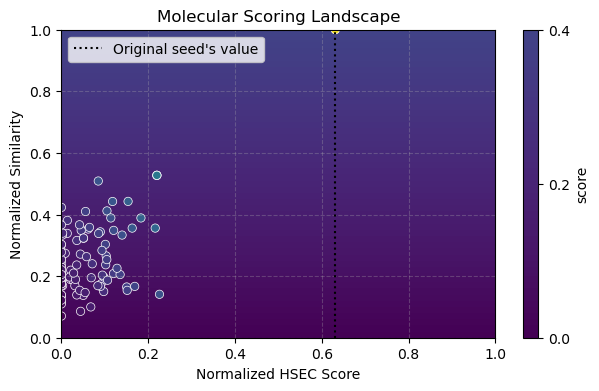

In [13]:
# get normalized values of molecules from scorer
x_scores = results.norm_qsar_aih_scores   ## Already normalized 0-1
y_scores = results.norm_similarity_scores  ## Already normalized 0-1

# set color for scatter
color = -1*results.combined_scores


# Create a uniform grid from 0 to 1
deltas = np.linspace(0, 1, 100)
Xgrid, Ygrid = np.meshgrid(deltas, deltas)

# Calculate scores across the entire grid
grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid*scorer.hsec_max + scorer.hsec_min)

# Plot everything
plt.figure(figsize=(7, 4))

# Plot contour background (0-1 range)
contour = plt.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
plt.colorbar(label='score', ticks=np.linspace(0,2,11))

# Plot reference line for seed value
plt.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Original seed's value")

# Plot data points (already normalized)
plt.scatter(x_scores, y_scores, c=color, edgecolor='white', linewidths=0.5, cmap='viridis')

plt.xlabel("Normalized HSEC Score") 
plt.ylabel("Normalized Similarity")
plt.title("Molecular Scoring Landscape")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.xlim(0, 1)
plt.ylim(0, 1)



## Controlled Generation with CMA-ES and the custom oracle

### Generate hidden state encoding for the imatinib seed to initialize CMA-ES

To start the CMA-ES optimization process, we first seed the optimizer with the hidden state encoding for our imatinib seed molecule using the `/hidden` endpoint.

In [14]:
# First calculate a hidden state representation of our seed, imatinib.
headers = {
    'accept': 'application/json',
    'Content-Type': 'application/json'
}
data = {
    "sequences": [m_seed],
}

# Get the response from the server
response = requests.post(hidden_url, headers=headers, json=data)
imatinib_hidden = np.squeeze(np.array(response.json()["hiddens"]))

# We can use this seed hidden state as a starting point for our CMA-ES optimizer
popsize = sampling_summary['valid_smiles']
sigma=1.0

# Initialize with zeros or the hidden state encoding for imatinib
#optimizer = cma.CMAEvolutionStrategy(np.zeros(imatinib_hidden.size, dtype=np.float32), sigma, {'popsize': popsize})
optimizer = cma.CMAEvolutionStrategy(imatinib_hidden, sigma, {'popsize': popsize})

(50_w,100)-aCMA-ES (mu_w=27.0,w_1=8%) in dimension 512 (seed=1059265, Fri Mar 14 09:41:54 2025)


Now that we've initialized the CMA-ES optimizer, we can generate and decode an initial set of trial encodings using the `/decode` endpoint.

In [15]:
# Generate and decode a set of initial trial encodings with CMA-ESecode trial encodings

trial_encodings=optimizer.ask(popsize)

headers = {
    'accept': 'application/json',
    'Content-Type': 'application/json'
}
hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
hiddens_json = {"hiddens":hiddens_array.tolist(),
                "mask": [[True] for i in range(hiddens_array.shape[0])]}


response = requests.post(decode_url, headers=headers, json=hiddens_json)
molecules = list(dict.fromkeys(response.json()['generated']))

We can then calculate the scores for this trial population and plot the results in our search space.

In [16]:
# score current draw
results = scorer.score(molecules, reference_smiles=m_seed)

# Sampling summary
print(len(molecules))

#~now scoring~#
#~Done scoring~#
96


In [17]:
# SET MANUALLY
metric='norm_qsar_aih_scores' # 'qsar_hsec_scores'

# Extract scores based on the chosen metric and convert to numpy arrays if needed
x_scores = np.array(getattr(results, metric))
y_scores = np.array(results.similarity_scores)


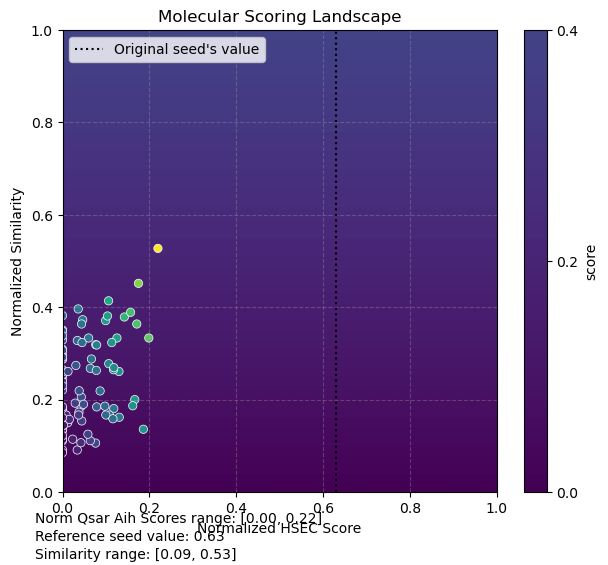

In [18]:
# Get combined scores for point coloring
color_values = -1 * np.array(results.combined_scores)

# Create a uniform grid from 0 to 1
deltas = np.linspace(0, 1, 100)
Xgrid, Ygrid = np.meshgrid(deltas, deltas)

# Calculate scores across the entire grid
grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid*scorer.hsec_max + scorer.hsec_min)

# Plot everything
plt.figure(figsize=(7, 6))

# Plot contour background (0-1 range)
contour = plt.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
plt.colorbar(label='score', ticks=np.linspace(0,2,11))

# Plot reference line for seed value
plt.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Original seed's value")

# Plot data points (already normalized)
plt.scatter(x_scores, y_scores, c=color_values, edgecolor='white', linewidths=0.5, cmap='viridis')

plt.xlabel("Normalized HSEC Score") 
plt.ylabel("Normalized Similarity")
plt.title("Molecular Scoring Landscape")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.xlim(0, 1)
plt.ylim(0, 1)

# Add annotations showing ranges and reference value
plt.annotate(f"{metric.replace('_', ' ').title()} range: [{np.min(x_scores):.2f}, {np.max(x_scores):.2f}]",
            xy=(0.05, 0.07), xycoords='figure fraction')

# Add annotation for seed value
plt.annotate(f"Reference seed value: {seed_score:.2f}", 
            xy=(0.05, 0.04), xycoords='figure fraction')

plt.annotate(f"Similarity range: [{np.min(y_scores):.2f}, {np.max(y_scores):.2f}]",
            xy=(0.05, 0.01), xycoords='figure fraction')
    
plt.show()


### Iterative optimization with CMA-ES and the custom oracle function
Now that we have our starting population, we can iteratively optimize using the CMA-ES strategy:

1. Generate a new set of trial encodings
2. Decode and calculate scores
3. Generate a new set of hidden state representations for valid trial candidates
4. Update the CMA-ES optimizer with the current combination of scores and hidden state representations

Note that through the CMA-ES optimization loop, we will occasionally encounter invalid SMILES depending on the search parameters.  We will stop the CMA-ES optimization loop if we have reduced our starting population by half.

In [19]:
popsize

100

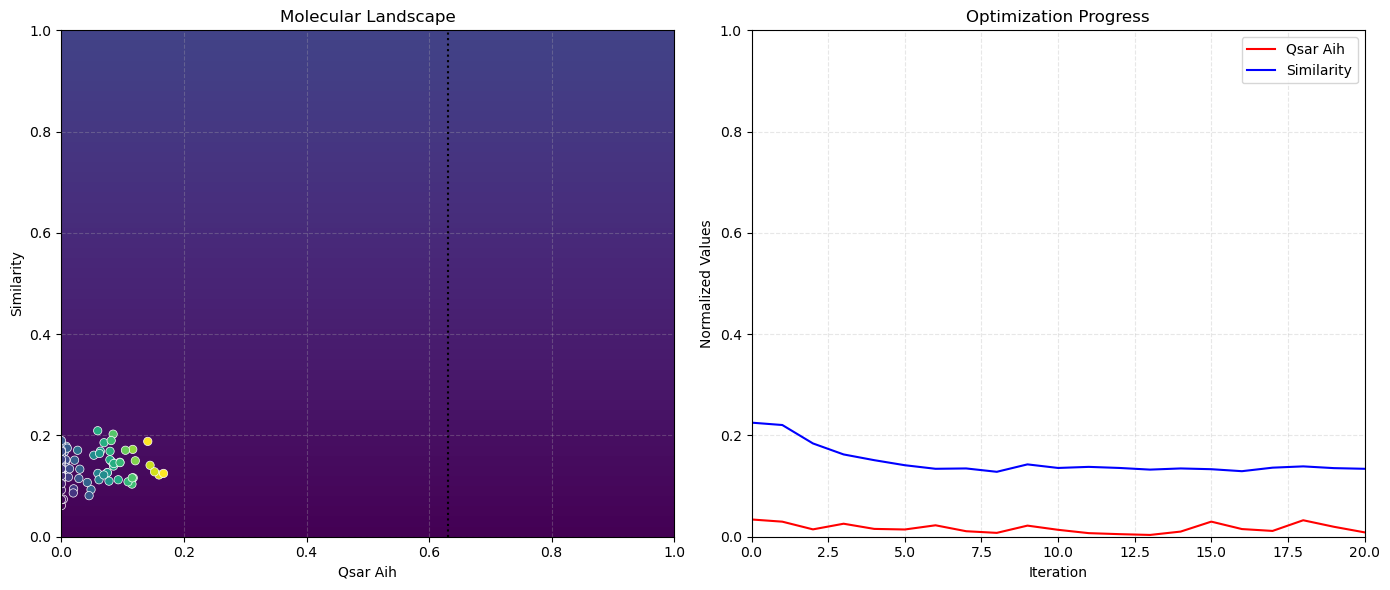

<Figure size 640x480 with 0 Axes>

Iter 20/20: Pop=90, Qsar Aih=0.01, Sim=0.13

Optimization complete!


In [20]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# Set the normalized metric to use
metric = 'norm_qsar_aih_scores'
raw_metric = metric.replace('norm_', '')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Initialize tracking lists for median values
med_scores = [np.median(np.array(getattr(results, metric)))]
med_sims = [np.median(np.array(results.norm_similarity_scores))]

# Set parameters for optimization
minpopsize = popsize/2
n_steps = 20

for i in range(n_steps):
    # Ask for trial encodings
    trial_encodings = optimizer.ask(popsize)
    # Decode to molecules
    hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
    hiddens_json = {"hiddens": hiddens_array.tolist(), "mask": [[True] for _ in range(hiddens_array.shape[0])]}
    response = requests.post(decode_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=hiddens_json)
    # Process valid molecules
    molecules = list(dict.fromkeys(response.json()['generated']))
    valid_smiles = [m for m in molecules if Chem.MolFromSmiles(m) is not None]
    # Get encodings for valid SMILES
    data = {"sequences": valid_smiles}
    response = requests.post(hidden_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=data)
    hiddens_array = np.squeeze(np.array(response.json()["hiddens"]))
    
    # Score molecules
    results = scorer.score(valid_smiles, reference_smiles=m_seed)
    popsize = len(results.combined_scores)
    
    # Check population size
    if popsize <= minpopsize:
        print(f"Stopping at minimum population size {popsize}")
        break
    
    # Update optimizer
    optimizer.tell(np.squeeze(np.array(hiddens_array)), results.combined_scores)
    
    # Extract normalized scores
    x_scores = np.array(getattr(results, metric))
    y_scores = np.array(results.norm_similarity_scores)
    color_values = -1 * np.array(results.combined_scores)

    ##### plots
    # Clear plots
    ax1.clear()
    ax2.clear()
    clear_output(wait=True)
    
    # Create grid for the background
    deltas = np.linspace(0, 1, 100)
    Xgrid, Ygrid = np.meshgrid(deltas, deltas)
    
    # calc grid scores ######## !!! ADAPT when change metric
    #grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid)
    grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid*scorer.hsec_max + scorer.hsec_min)
    
    # Plot 1: Molecular landscape
    contour = ax1.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
    # Plot reference line for seed value (assuming it's already normalized)
    ax1.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Seed")
    
    # Plot data points
    scatter = ax1.scatter(x_scores, y_scores, c=color_values, edgecolor='white', linewidths=0.5, cmap='viridis')
    # Set labels and appearance
    metric_label = metric.replace('norm_', '').replace('_scores', '').replace('_', ' ').title()
    ax1.set_xlabel(f"{metric_label}")
    ax1.set_ylabel("Similarity")
    ax1.set_title("Molecular Landscape")
    ax1.grid(alpha=0.3, linestyle='--')
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    # Update tracking lists
    med_scores.append(np.median(x_scores))
    med_sims.append(np.median(y_scores))
    
    # Plot 2: Progress tracking
    ax2.plot(med_scores, color='red', label=metric_label)
    ax2.plot(med_sims, color='blue', label='Similarity')
    ax2.set_ylabel("Normalized Values")
    ax2.set_xlabel("Iteration")
    ax2.set_xlim(0, n_steps)
    ax2.set_ylim(0, 1)
    ax2.grid(alpha=0.3, linestyle='--')
    ax2.legend()
    ax2.set_title("Optimization Progress")
    
    # Display figure
    plt.tight_layout()
    display(fig)
    plt.pause(0.1)
    
    print(f"Iter {i+1}/{n_steps}: Pop={popsize}, {metric_label}={med_scores[-1]:.2f}, Sim={med_sims[-1]:.2f}")

print("\nOptimization complete!")

## Viewing the resulting optimized molecules.

In [21]:
len(valid_smiles)

90

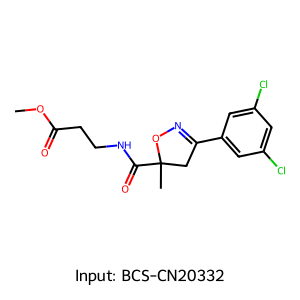

In [22]:
input_mol = Chem.MolFromSmiles(m_seed)

Draw.MolToImage(input_mol, legend=str(f"Input: {m_seed_name}" ), subImgSize=(350,360))

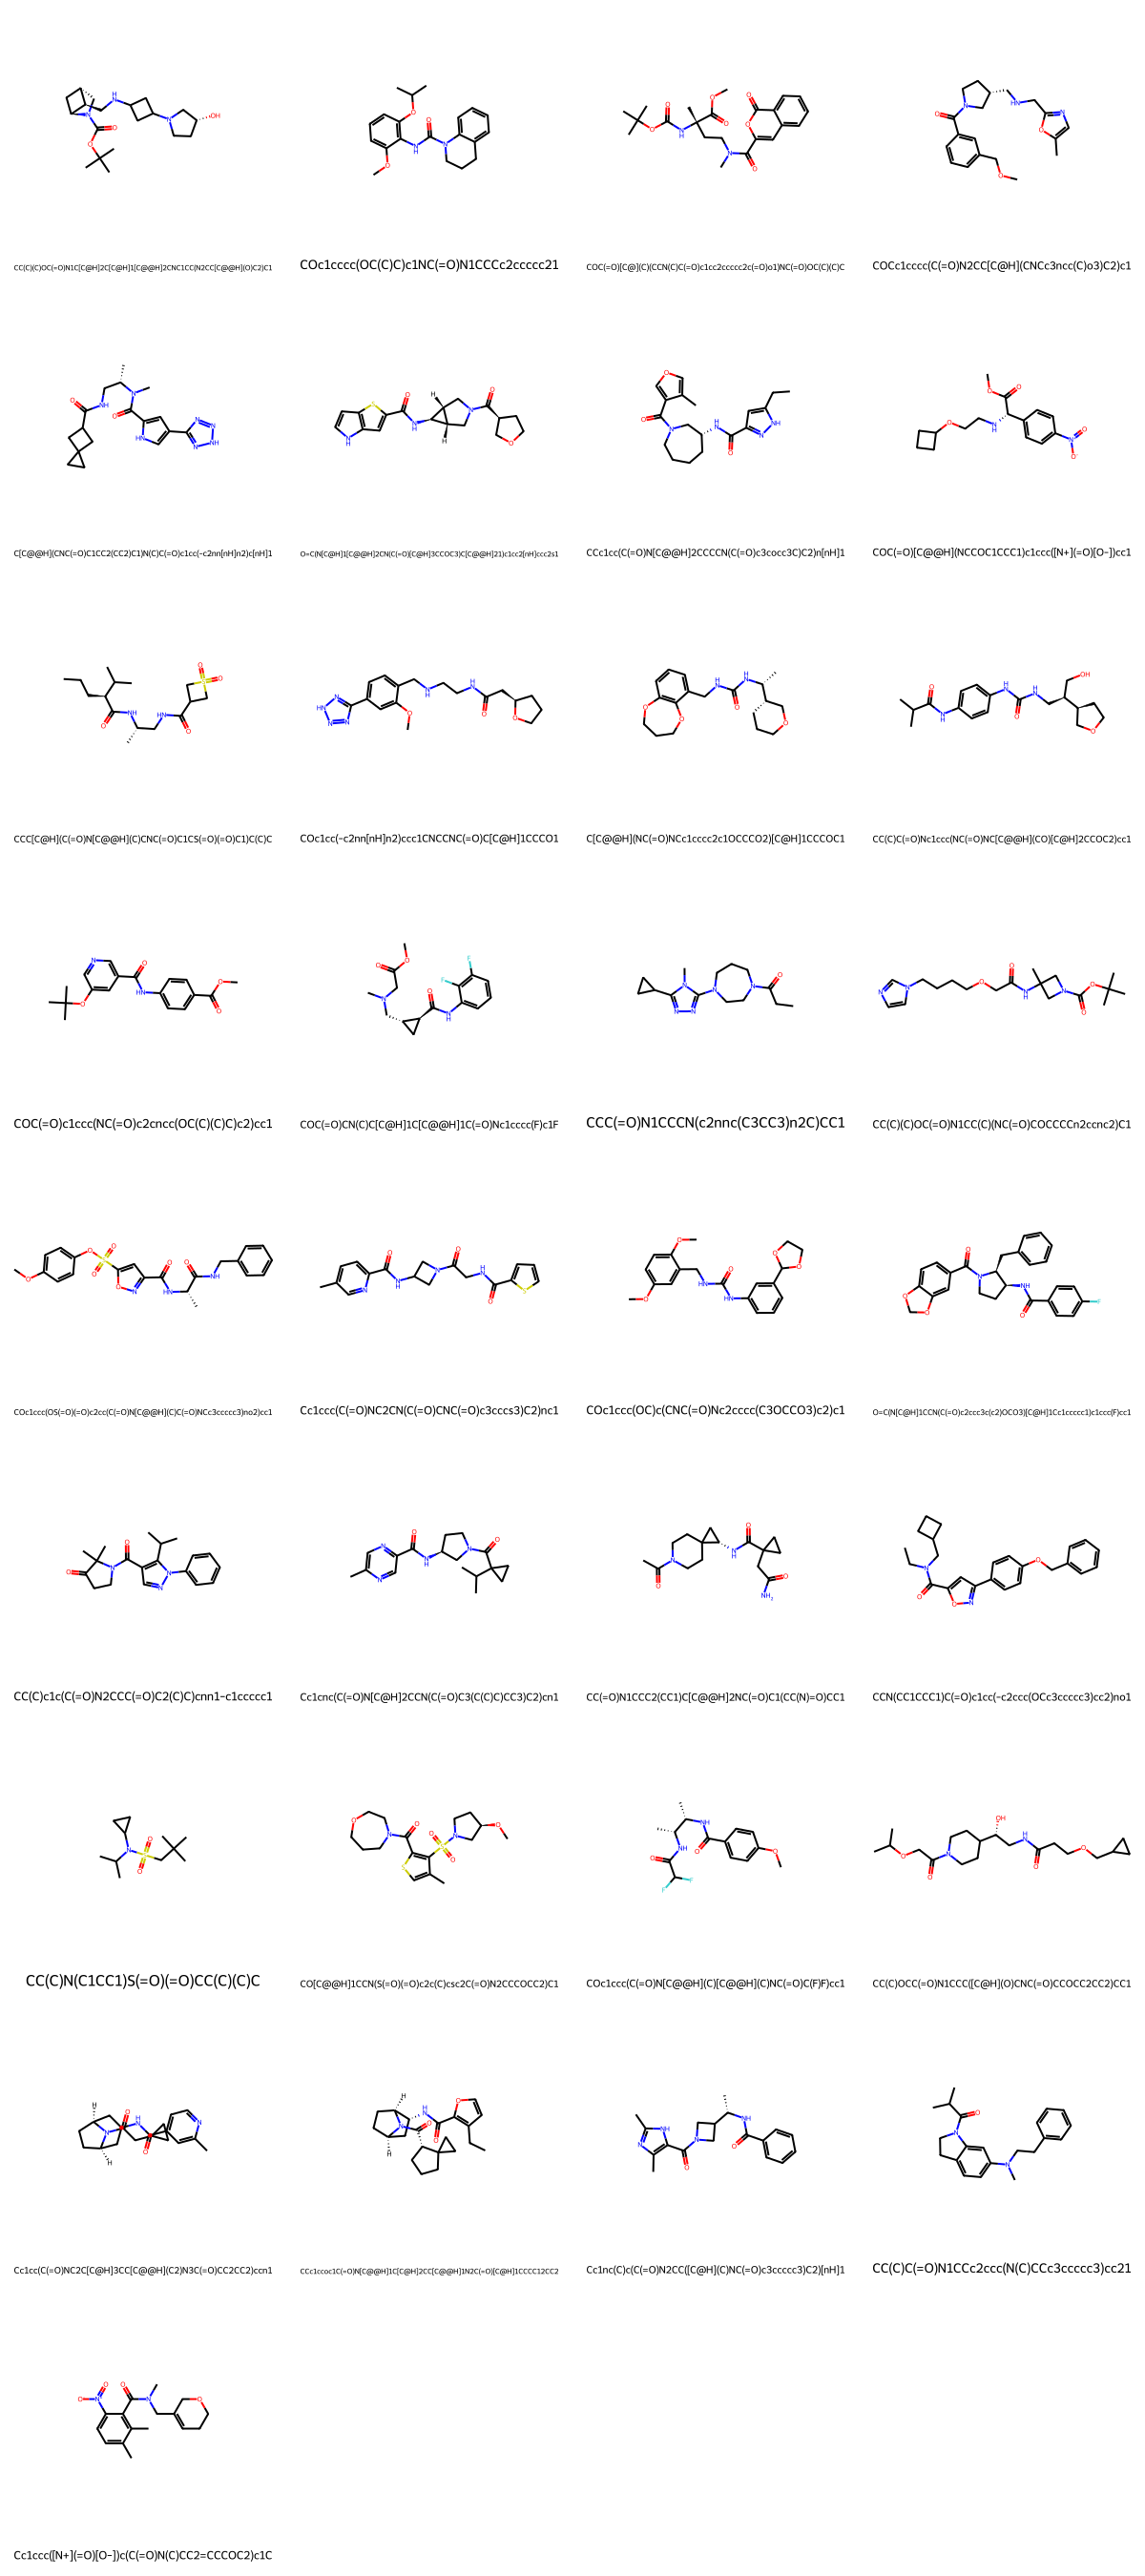

In [23]:
Draw.MolsToGridImage([Chem.MolFromSmiles(smile, sanitize=False) for smile in valid_smiles[:33]],
                     legends=molecules, molsPerRow=4, subImgSize=(300, 300))

In [35]:
list_w_seed

['CC(C)(C)OC(=O)N1C[C@H]2C[C@H]1[C@@H]2CNC1CC(N2CC[C@@H](O)C2)C1',
 'COc1cccc(OC(C)C)c1NC(=O)N1CCCc2ccccc21',
 'COC(=O)[C@](C)(CCN(C)C(=O)c1cc2ccccc2c(=O)o1)NC(=O)OC(C)(C)C',
 'COCc1cccc(C(=O)N2CC[C@H](CNCc3ncc(C)o3)C2)c1',
 'C[C@@H](CNC(=O)C1CC2(CC2)C1)N(C)C(=O)c1cc(-c2nn[nH]n2)c[nH]1',
 'O=C(N[C@H]1[C@@H]2CN(C(=O)[C@H]3CCOC3)C[C@@H]21)c1cc2[nH]ccc2s1',
 'CCc1cc(C(=O)N[C@@H]2CCCCN(C(=O)c3cocc3C)C2)n[nH]1',
 'COC(=O)[C@@H](NCCOC1CCC1)c1ccc([N+](=O)[O-])cc1',
 'CCC[C@H](C(=O)N[C@@H](C)CNC(=O)C1CS(=O)(=O)C1)C(C)C',
 'COc1cc(-c2nn[nH]n2)ccc1CNCCNC(=O)C[C@H]1CCCO1',
 'C[C@@H](NC(=O)NCc1cccc2c1OCCCO2)[C@H]1CCCOC1',
 'CC(C)C(=O)Nc1ccc(NC(=O)NC[C@@H](CO)[C@H]2CCOC2)cc1',
 'COC(=O)c1ccc(NC(=O)c2cncc(OC(C)(C)C)c2)cc1',
 'COC(=O)CN(C)C[C@H]1C[C@@H]1C(=O)Nc1cccc(F)c1F',
 'CCC(=O)N1CCCN(c2nnc(C3CC3)n2C)CC1',
 'CC(C)(C)OC(=O)N1CC(C)(NC(=O)COCCCCn2ccnc2)C1',
 'COc1ccc(OS(=O)(=O)c2cc(C(=O)N[C@@H](C)C(=O)NCc3ccccc3)no2)cc1',
 'Cc1ccc(C(=O)NC2CN(C(=O)CNC(=O)c3cccs3)C2)nc1',
 'COc1ccc(OC)c(CNC(=O)Nc2ccc


--> Test mit 'COc1cc(-c2nn[nH]n2)ccc1CNCCNC(=O)C[C@H]1CCCO1'
--> Add Cl instead of CO --> 'Clc1cc(-c2nn[nH]n2)ccc1CNCCNC(=O)C[C@H]1CCCO1'


result_score_adjusted_1 = scorer.score([adjusted_1], reference_smiles=m_seed)
result_score_adjusted_2 = scorer.score([adjusted_2], reference_smiles=m_seed)
result_score_adjusted_3 = scorer.score([adjusted_3], reference_smiles=m_seed
aih_score_adjusted_1 = result_score_adjusted_1.norm_qsar_aih_scores[0]
print (aih_score_adjusted_1)

In [9]:
#generated molecule
generated_not_adjusted = 'COCc1cccc(C(=O)N2CC[C@H](CNCc3ncc(C)o3)C2)c1'
# Adjust from genereated plus CL
adjusted_gen_Cl = 'ClCc1cccc(C(=O)N2CC[C@H](CNCc3ncc(C)o3)C2)c1'
# adjusted 3 chlorid(s) deleted from seed
adjusted_seed_Cl = "COC(=O)CCNC(=O)C1(C)CC(c2cccc(Cl)c2)=NO1"
adjusted_seed_ClCl = "COC(=O)CCNC(=O)C1(C)CC(c2ccccc2)=NO1"
#input seed
seedinput = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#from QED optimized dataset
QED_optimized ='COC(=O)CCNC(=O)c1ccc(-c2ccccc2)c(Cl)c1'

#Draw.MolToImage(input_mol, legend=str(f"Input: {test_substance}" ), subImgSize=(350,360))

In [10]:
result_score_generated_not_adjusted = scorer.score([generated_not_adjusted], reference_smiles=m_seed)
result_score_adjusted_gen_Cl = scorer.score([adjusted_gen_Cl], reference_smiles=m_seed)
result_score_adjusted_seed_Cl = scorer.score([adjusted_seed_Cl], reference_smiles=m_seed)
result_score_adjusted_seed_ClCl = scorer.score([adjusted_seed_ClCl], reference_smiles=m_seed)
result_score_seedinput = scorer.score([seedinput], reference_smiles=m_seed)
result_score_QED = scorer.score([QED_optimized], reference_smiles=m_seed)

NameError: name 'scorer' is not defined

In [6]:
names_samples =["generated_not_adjusted", "adjusted_gen_Cl", "adjusted_seed_Cl", "adjusted_seed_ClC", "seedinput", "QED_optimized"]
samples = [generated_not_adjusted, adjusted_gen_Cl, adjusted_seed_Cl, adjusted_seed_ClCl, seedinput, QED_optimized]

In [8]:
import pandas as pd
df_manual = pd.DataFrame()
data_manual = {'Name': names_samples, 'AIH Score': [result_score_generated_not_adjusted.norm_qsar_aih_scores, result_score_adjusted_gen_Cl.norm_qsar_aih_scores, result_score_adjusted_seed_Cl.norm_qsar_aih_scores, result_score_adjusted_seed_ClCl = scorer.score([adjusted_seed_ClCl], reference_smiles=m_seed).norm_qsar_aih_scores, result_score_seedinput.norm_qsar_aih_scores, result_score_QED.norm_qsar_aih_scores]}
print (data_manual)
df_manual = pd.DataFrame(data_manual)
print(df_manual)

#aih_score_adjusted_1 = result_score_adjusted_1.norm_qsar_aih_scores[0]
#print (aih_score_adjusted_1)

SyntaxError: invalid syntax. Maybe you meant '==' or ':=' instead of '='? (2311128671.py, line 3)

In [36]:
list_w_seed = valid_smiles + [m_seed]

In [34]:
# Test molecule scoring and access predictions and metrics
results_score = scorer.score(list_w_seed, reference_smiles=m_seed)
final_scores = results_score.norm_qsar_aih_scores[0]
print(f"QSAR-SIP: {results_score.qsar_aih_scores}")
print("####")
print(f"QSAR-SIP Normalized: {results_score.norm_qsar_aih_scores}")

#~now scoring~#
#~Done scoring~#
QSAR-SIP: [19.34, -0.18, 34.01, 46.58, 21.15, 46.92, 2.63, 25.43, -13.33, 23.7, 41.8, -7.08, 32.69, 1.78, 46.07, -28.55, 3.1, 10.58, 33.77, 23.78, 2.38, -44.4, -5.02, 8.59, -8.22, -27.39, 38.13, -42.46, 2.89, 29.89, -8.74, 31.06, 43.49, -14.44, 37.09, -52.03, 57.88, 1.25, -18.59, -13.53, -31.23, -5.18, 31.64, 2.65, -24.71, 27.81, 48.24, 7.96, -7.43, 18.08, 63.71, 46.22, 3.82, 4.56, -11.19, -39.76, 12.01, 34.19, 32.5, 24.52, -28.41, -17.31, -6.38, 24.9, -3.79, -23.98, -8.31, -4.04, -18.43, -19.67, 5.32, 16.9, -30.31, 7.74, -5.1, 30.03, 11.38, 56.38, 31.76, -1.77, -23.16, 66.66, -16.68, -8.22, -31.79, -36.17, 38.28, -17.24, 60.77, 27.63, 252.43]
####
QSAR-SIP Normalized: [0.04835, 0.0, 0.08502499999999999, 0.11645, 0.052875, 0.1173, 0.006575, 0.06357499999999999, 0.0, 0.05925, 0.1045, 0.0, 0.08172499999999999, 0.00445, 0.115175, 0.0, 0.00775, 0.02645, 0.08442500000000001, 0.05945, 0.0059499999999999996, 0.0, 0.0, 0.021475, 0.0, 0.0, 0.09532500000000001, 0

In [30]:
seed_score


0.631075

asdfasd

In [ ]:
### code Gil



In [31]:
import pandas as pd
df = pd.DataFrame({"valid_smiles": valid_smiles })

In [32]:
import helper
df['LogP'] = df['valid_smiles'].apply(helper.calculate_logp)
df['QED'] = df['valid_smiles'].apply(helper.calculate_qed)

In [33]:
df.sort_values(["QED"], inplace=True, ascending=False)
df.head(10)

,valid_smiles,LogP,QED
37,Cc1csc(C(=O)N2CC[C@H](NC(=O)c3ccco3)C2)c1,2.29402,0.946098
19,Cc1ccccc1CN1CC[C@@H](NC(=O)c2ccccc2)C[C@H]1C,3.77792,0.928940
31,Cc1cc(C(=O)N2CC[C@@H](NC(=O)[C@@H]3C[C@H]3c3cc...,2.52442,0.922549
52,Cc1ccc(O[C@@H](C)C(=O)NN2CCCc3cc(F)c(F)cc32)cc1,3.52452,0.920901
51,COC1(C(=O)N2CC[C@H]3CCN(C(=O)c4ccc[nH]4)[C@H]3...,1.64680,0.915716
6,COCC(C)(C)C(=O)Nc1nc(C(C)(C)C)cs1,3.05170,0.914528
9,CS(=O)(=O)N1CCC[C@H](CNC(=O)c2ccc(F)cc2)C1,1.22710,0.908734
50,COCCC(=O)N[C@@H]1CC[C@H](C)N(C(=O)c2ccc(F)cc2)C1,1.97150,0.901551
89,CCc1cc(C(=O)N2CC[C@H](NC(=O)c3cccs3)C2)n[nH]1,1.67810,0.900069
40,COCCC(=O)N1CC[C@H](NC(=O)c2ccc(F)cc2)[C@H](C)C1,1.82900,0.899606


In [34]:
#df.to_csv('../../data/interim/molmim/guided/molmmim_QSAR_AIH_BCS-CN20332.csv', index=False, sep=';', header=True, mode='x') 
#../../data/interim/molmmim_BCS-CN20332_LogP_sim03_100p_100m
#../../data/interim/XXX.csv

## Second Seed